# Notebook 6 - Route 11: clean, train, and explain

**Question:** can historical information improve Route 11 arrival predictions over the published timetable?

Route 11 runs between Downtown Station and Eastwood Meadows. We apply the Route 7 research procedure, but fit new coefficients, feature choices, and historical summaries.

## Before running
Put `RTS_Route11_Spring2023.xlsx` and `RTS_GTFS_Spring2023.zip` in the **same folder** as this notebook. Select the Python kernel and run top to bottom. Executed results and a plot are included. No previous notebook or prepared CSV is required. Original files are never overwritten.

| Section | Purpose |
|---|---|
| 1 | Load libraries, show the dataframe, and follow one bus |
| 2 | Clean fields and flag questionable records |
| 3 | Read the applicable historical schedule |
| 4 | Match scheduled visits and check journey evidence |
| 5 | Keep intermediate arrival labels and fixed date splits |
| 6 | Explain regression statistics and backward selection |
| 7 | Compare schedule, median, regression, ridge, and forest |
| 8 | Interpret results and answer research questions |

**Delay = actual arrival minus scheduled arrival**, in minutes. Positive means late. **Predicted arrival = scheduled arrival + predicted delay.**

We model only explicitly timed intermediate stops. We do not invent times for untimed stops or treat terminal arrival as departure. Schedule assignments remain provisional.

**No look-ahead predictors:** only direction, scheduled hour, weekday, and stop ID are used. Bus ID, actual arrival, passenger counts recorded at the target stop, audit fields, and outlier flags are excluded. Retrospective journey checks support labels; they do not establish a live matcher. Every fold fits preprocessing, feature selection, and ridge tuning on earlier dates only. Final-test outcomes remain unscored.

## 1. Load libraries and inspect the dataframe

Each row is a stop visit, not a complete trip. Stop ID is a location; stop sequence is its position within a direction. One bus repeats the route throughout the day.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import zipfile
from itertools import combinations
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

raw = pd.read_excel("RTS_Route11_Spring2023.xlsx", engine="openpyxl")
display(raw.head())
print("Stop visits:", len(raw), "Buses:", raw.Bus.nunique(), "Dates:", raw.Date.nunique())
display(raw.isna().sum().to_frame("missing_values"))

Stop visits: 23365 Buses: 3 Dates: 17


,Route,Stop ID,Stop Name,Stop Seq ID,Day of Week,Date,Arrive,Passenger On,Passenger Off,Passenger Load,Passenger Miles,Interstop Distance,Bus,Lat.,Long.
0,11-Downtown Station To Eastwood Meadows,1,Rosa Parks RTS Downtown Station,0,Wednesday,2023-03-01,09:26:33,1,0,1,0.000,0.00,710,29.64576,-82.32235
1,11-Downtown Station To Eastwood Meadows,1206,Arlington Square Apartments,1,Wednesday,2023-03-01,09:31:57,0,0,1,0.057,0.06,710,29.64978,-82.32237
2,11-Downtown Station To Eastwood Meadows,553,Downtown Library,2,Wednesday,2023-03-01,09:32:48,0,0,1,0.156,0.16,710,29.65196,-82.32224
3,11-Downtown Station To Eastwood Meadows,554,Salvation Army,3,Wednesday,2023-03-01,09:33:27,0,0,1,0.292,0.29,710,29.65186,-82.31752
4,11-Downtown Station To Eastwood Meadows,555,Eastbound E University Avenue @ SE 8th Street,4,Wednesday,2023-03-01,09:33:39,0,0,1,0.076,0.08,710,29.65187,-82.31629


,missing_values
Route,0
Stop ID,0
Stop Name,0
Stop Seq ID,0
Day of Week,0
Date,0
Arrive,0
Passenger On,0
Passenger Off,0
Passenger Load,0


### Read the features

| Columns | Meaning and role |
|---|---|
| Date, Arrive | Recorded arrival timestamp: used to calculate the target |
| Bus | Vehicle ID: trace records and inspect errors |
| Stop ID, Stop Name | Location labels; numeric IDs do not imply order |
| Stop Seq ID | Ordered position within a direction; resets between journeys |
| Passenger On/Off/Load | Activity recorded at the stop; unavailable before that arrival |
| Lat., Long. | Recorded location; possible support for later quality checks |
| Passenger Miles, Interstop Distance | Operational measures, unused in this first model |

Do not pass every numeric column to the model. Information recorded during the arrival being predicted can reveal the answer.

## 2. Clean a working copy and inspect a bus-day

Preserve `source_row` to trace an observation back to Excel (Excel row = source_row + 2). Remove only exact full-row copies. Standardize identifiers and timestamps, then flag invalid IDs/sequences, repeated keys, and tied times. Flags require review; they do not prove an observation is wrong.

In [2]:
data = raw.copy()
data["source_row"] = data.index
data = data.drop_duplicates(subset=raw.columns.tolist()).copy()
data["bus_id"] = data["Bus"].astype("string")
data["stop_id"] = data["Stop ID"].astype("string").str.replace(r"\.0$", "", regex=True)
data["stop_sequence"] = pd.to_numeric(data["Stop Seq ID"], errors="coerce")
data["service_date"] = pd.to_datetime(data["Date"], errors="coerce").dt.normalize()
clock = pd.to_timedelta(data["Arrive"].astype(str), errors="coerce")
clock = clock.where((clock >= pd.Timedelta(0)) & (clock < pd.Timedelta(days=1)))
data["actual_arrival"] = data["service_date"] + clock

print("Rows before:", len(raw), "After exact-copy rule:", len(data))
display(data[["source_row", "bus_id", "stop_id", "stop_sequence", "actual_arrival"]].head())
bad_fields = (
    data[["bus_id", "stop_id", "stop_sequence", "actual_arrival"]].isna().any(axis=1)
    | (data["stop_sequence"] < 0) | (data["stop_sequence"] % 1 != 0)
    | (data["stop_sequence"] == 999) | data["stop_id"].eq("9999").fillna(True)
)
repeated_key = data.duplicated(["bus_id", "service_date", "stop_id", "actual_arrival"], keep=False)
tied_time = data.duplicated(["bus_id", "service_date", "actual_arrival"], keep=False)
data["needs_review"] = bad_fields | repeated_key | tied_time

display(pd.Series({"invalid_fields": int(bad_fields.sum()),
                   "repeated_key_rows": int(repeated_key.sum()),
                   "tied_time_rows": int(tied_time.sum())}).to_frame("flagged_rows"))
display(data.loc[data["needs_review"], ["source_row", "bus_id", "stop_id", "actual_arrival"]].head(6))

Rows before: 23365 After exact-copy rule: 23365


,source_row,bus_id,stop_id,stop_sequence,actual_arrival
0,0,710,1,0,2023-03-01 09:26:33
1,1,710,1206,1,2023-03-01 09:31:57
2,2,710,553,2,2023-03-01 09:32:48
3,3,710,554,3,2023-03-01 09:33:27
4,4,710,555,4,2023-03-01 09:33:39


,flagged_rows
invalid_fields,23
repeated_key_rows,1454
tied_time_rows,1516


,source_row,bus_id,stop_id,actual_arrival
32,32,710,1560,2023-03-01 09:49:21
33,33,710,1560,2023-03-01 09:49:21
61,61,710,1,2023-03-01 10:20:29
62,62,710,1,2023-03-01 10:20:29
94,94,710,1560,2023-03-01 10:53:22
95,95,710,1560,2023-03-01 10:53:22


In [3]:
bus_summary = data.groupby(["bus_id", "service_date"]).agg(visits=("source_row", "size"), first_arrival=("actual_arrival", "min"), last_arrival=("actual_arrival", "max")).reset_index()
display(bus_summary.head(10))
bus, day = data.bus_id.iloc[0], data.service_date.iloc[0]
one_bus_day = data.loc[data.bus_id.eq(bus) & data.service_date.eq(day)]
display(one_bus_day[["source_row", "bus_id", "Stop Name", "stop_sequence", "actual_arrival", "needs_review"]].head(15))
all_dates = sorted(data.service_date.dropna().unique())
train_dates, validation_dates, reserved_dates = all_dates[:10], all_dates[10:13], all_dates[13:]
for label, dates in [("Train", train_dates), ("Validation", validation_dates), ("Reserved final test", reserved_dates)]:
    print(label, [str(pd.Timestamp(d).date()) for d in dates])

Train ['2023-03-01', '2023-03-02', '2023-03-03', '2023-03-06', '2023-03-07', '2023-03-08', '2023-03-09', '2023-03-10', '2023-03-13', '2023-03-14']
Validation ['2023-03-15', '2023-03-16', '2023-03-17']
Reserved final test ['2023-03-20', '2023-03-21', '2023-03-22', '2023-03-23']


,bus_id,service_date,visits,first_arrival,last_arrival
0,2111,2023-03-01,883,2023-03-01 05:30:30,2023-03-01 19:49:13
1,2111,2023-03-02,875,2023-03-02 05:30:23,2023-03-02 20:02:06
2,2111,2023-03-03,883,2023-03-03 05:30:34,2023-03-03 19:45:30
3,2111,2023-03-06,883,2023-03-06 05:30:03,2023-03-06 19:50:53
4,2111,2023-03-07,859,2023-03-07 05:30:07,2023-03-07 19:47:12
5,2111,2023-03-08,883,2023-03-08 05:30:09,2023-03-08 19:47:44
6,2111,2023-03-09,883,2023-03-09 05:30:17,2023-03-09 19:43:41
7,2111,2023-03-10,884,2023-03-10 05:29:53,2023-03-10 19:46:36
8,2111,2023-03-13,873,2023-03-13 05:31:59,2023-03-13 20:00:45
9,2111,2023-03-14,883,2023-03-14 05:33:01,2023-03-14 20:02:28


,source_row,bus_id,Stop Name,stop_sequence,actual_arrival,needs_review
0,0,710,Rosa Parks RTS Downtown Station,0,2023-03-01 09:26:33,False
1,1,710,Arlington Square Apartments,1,2023-03-01 09:31:57,False
2,2,710,Downtown Library,2,2023-03-01 09:32:48,False
3,3,710,Salvation Army,3,2023-03-01 09:33:27,False
4,4,710,Eastbound E University Avenue @ SE 8th Street,4,2023-03-01 09:33:39,False
5,5,710,Northbound NE 9th Street @ E University Avenue,5,2023-03-01 09:33:41,False
6,6,710,Northbound NE 9th Street @ NE 3rd Avenue,6,2023-03-01 09:34:10,False
7,7,710,Northbound NE 9th Street @ NE 5th Avenue,7,2023-03-01 09:34:15,False
8,8,710,Northbound NE 9th Street @ NE 8th Avenue,8,2023-03-01 09:35:27,False
9,9,710,Eastbound NE 8th Avenue @ NE 11th Street,9,2023-03-01 09:35:57,False


## 3. Read the historical timetable and service calendar

GTFS contains trips, stop patterns, and published times. The calendar and exceptions identify active trips on each date. Blank arrival-time fields are not published intermediate times and are excluded. Inspect Route 11's own timed stops instead of carrying over Route 7's stop IDs or sequence numbers.

In [4]:
def read_schedule_table(filename):
    with zipfile.ZipFile("RTS_GTFS_Spring2023.zip") as archive:
        table = pd.read_csv(archive.open(filename), dtype=str, keep_default_na=False)
    table.columns = table.columns.str.strip()
    return table.apply(lambda column: column.str.strip())

trips = read_schedule_table("trips.txt")
stop_times = read_schedule_table("stop_times.txt")
calendar = read_schedule_table("calendar.txt")
exceptions = read_schedule_table("calendar_dates.txt")
stops = read_schedule_table("stops.txt")

route11_trips = trips.loc[trips["route_id"] == "11"]
display(route11_trips[["trip_id", "direction_id", "service_id", "trip_headsign"]].head())
route11_times = route11_trips.merge(stop_times, on="trip_id", validate="one_to_many")
route11_times = route11_times.loc[route11_times["arrival_time"] != ""].copy()
route11_times = route11_times.merge(stops[["stop_id", "stop_name"]], on="stop_id", validate="many_to_one")

scheduled_days = []
for date in sorted(data["service_date"].dropna().unique()):
    date = pd.Timestamp(date)
    date_code = date.strftime("%Y%m%d")
    active = set(calendar.loc[
        (calendar["start_date"] <= date_code) & (calendar["end_date"] >= date_code)
        & (calendar[date.day_name().lower()] == "1"), "service_id"
    ])
    for change in exceptions.loc[exceptions["date"] == date_code].itertuples(index=False):
        if change.exception_type == "1":
            active.add(change.service_id)
        elif change.exception_type == "2":
            active.discard(change.service_id)
    day_schedule = route11_times.loc[route11_times["service_id"].isin(active)].copy()
    day_schedule["service_date"] = date
    day_schedule["scheduled_arrival"] = date + pd.to_timedelta(day_schedule["arrival_time"])
    scheduled_days.append(day_schedule)

schedule = pd.concat(scheduled_days, ignore_index=True)
schedule["stop_sequence"] = pd.to_numeric(schedule["stop_sequence"])
display(schedule[["service_date", "trip_id", "direction_id", "stop_id", "scheduled_arrival"]].head())

,trip_id,direction_id,service_id,trip_headsign
1584,5011001,1,SWB,To Downtown Station
1585,5011003,1,SWB,To Downtown Station
1586,5011005,1,SWB,To Downtown Station
1587,5011007,1,SWB,To Downtown Station
1588,5011009,1,SWB,To Downtown Station


,service_date,trip_id,direction_id,stop_id,scheduled_arrival
0,2023-03-01,1011001,1,1560,2023-03-01 05:30:00
1,2023-03-01,1011001,1,1235,2023-03-01 05:40:00
2,2023-03-01,1011001,1,1,2023-03-01 05:50:00
3,2023-03-01,1011003,1,1560,2023-03-01 06:30:00
4,2023-03-01,1011003,1,1235,2023-03-01 06:40:00


In [5]:
trip_patterns = route11_trips.merge(stop_times, on="trip_id")
trip_patterns["seq"] = pd.to_numeric(trip_patterns.stop_sequence)
full_patterns = {tid: list(zip(g.sort_values("seq")["seq"], g.sort_values("seq").stop_id)) for tid, g in trip_patterns.groupby("trip_id")}
trip_last_sequence = {tid: max(seq for seq, stop in pattern) for tid, pattern in full_patterns.items()}
display(schedule[["direction_id", "stop_sequence", "stop_id", "stop_name"]].drop_duplicates().sort_values(["direction_id", "stop_sequence"]))
dev = data.loc[data.service_date.isin(train_dates + validation_dates)].sort_values(["bus_id", "service_date", "source_row"]).copy()
planned = schedule.loc[schedule.service_date.isin(train_dates + validation_dates)].copy()

,direction_id,stop_sequence,stop_id,stop_name
45,0,0,1,Rosa Parks RTS Downtown Station
46,0,13,1234,NE Walmart Supercenter
89,0,22,107,Health Department
47,0,32,1560,Eastwood Meadows
0,1,0,1560,Eastwood Meadows
120,1,11,107,Health Department
1,1,19,1235,NE Walmart Supercenter
2,1,28,1,Rosa Parks RTS Downtown Station


## 4. Propose schedule links, then check surrounding journeys

Join on date + stop ID + sequence position. Keep a unique scheduled candidate within 20 minutes, then remove competing claims on one scheduled visit. This **infers** a scheduled trip; the raw workbook has no direct trip ID.

The matching window can exclude extreme delays and create ambiguity when service is frequent. Scores therefore describe the retained population. A training-only window-coverage table is shown below; we do not pick a window based on validation errors.

The journey audit checks stop-pattern consistency, increasing source timestamps, and a unique scheduled trip supported by **other timepoints**, leaving the target arrival out of that corroboration. Terminal timestamps may support a historical assignment while still being unsuitable departure-delay labels. These checks improve evidence but do not independently verify ground truth.

In [6]:
observations = dev.loc[~dev.needs_review].copy()
candidates = observations.merge(planned, on=["service_date", "stop_id", "stop_sequence"], how="inner")
candidates["matching_gap_minutes"] = (candidates.actual_arrival - candidates.scheduled_arrival).dt.total_seconds().abs() / 60
MATCH_WINDOW_MINUTES = 20
possible = candidates.loc[candidates.matching_gap_minutes.le(MATCH_WINDOW_MINUTES)].copy()
possible["candidate_count"] = possible.groupby("source_row").source_row.transform("size")
matched = possible.loc[possible.candidate_count.eq(1)].copy()
conflict = matched.duplicated(["service_date", "trip_id", "stop_sequence"], keep=False)
conflict_review = matched.loc[conflict].copy()
matched = matched.loc[~conflict].copy()
print("Proposed unique development matches:", len(matched), "Conflicting claims held:", len(conflict_review))
display(matched[["source_row", "bus_id", "service_date", "stop_id", "direction_id", "scheduled_arrival", "actual_arrival"]].head(8))
coverage = []
for minutes in [10, 15, 20, 25, 30]:
    trial = candidates.loc[candidates.service_date.isin(train_dates) & candidates.matching_gap_minutes.le(minutes)]
    counts = trial.groupby("source_row").size()
    coverage.append({"window_minutes": minutes, "unique_candidates_before_conflict_check": int(counts.eq(1).sum()), "ambiguous_records": int(counts.gt(1).sum())})
display(pd.DataFrame(coverage))

Proposed unique development matches: 835 Conflicting claims held: 4


,source_row,bus_id,service_date,stop_id,direction_id,scheduled_arrival,actual_arrival
0,493,2111,2023-03-01,1560,1,2023-03-01 05:30:00,2023-03-01 05:30:30
23,512,2111,2023-03-01,1235,1,2023-03-01 05:40:00,2023-03-01 05:40:10
46,535,2111,2023-03-01,1234,0,2023-03-01 06:07:00,2023-03-01 06:11:26
69,574,2111,2023-03-01,1235,1,2023-03-01 06:40:00,2023-03-01 06:41:24
92,597,2111,2023-03-01,1234,0,2023-03-01 07:07:00,2023-03-01 07:11:02
115,636,2111,2023-03-01,1235,1,2023-03-01 07:40:00,2023-03-01 07:42:33
138,659,2111,2023-03-01,1234,0,2023-03-01 08:07:00,2023-03-01 08:11:07
161,698,2111,2023-03-01,1235,1,2023-03-01 08:40:00,2023-03-01 08:41:39


,window_minutes,unique_candidates_before_conflict_check,ambiguous_records
0,10,639,0
1,15,651,0
2,20,644,8
3,25,619,33
4,30,309,343


### Journey audit support

The following helper functions repeat the journey-evidence checks introduced for Route 7, with Route 11's own stop patterns and endpoints. Focus on the output counts first; inspect the helper code when reviewing a particular match. Source-order blocks are inferred at sequence resets and are not official trip IDs.

In [7]:
# Audit development dates only. Do not use final-test outcomes to change rules.
development_dates=sorted(data.service_date.dropna().unique())[:13]
dev=data[data.service_date.isin(development_dates)].sort_values(['bus_id','service_date','source_row']).copy()
planned=schedule[schedule.service_date.isin(development_dates)].copy()
matched=matched[matched.service_date.isin(development_dates)].copy()
g=dev.groupby(['bus_id','service_date'],sort=False)
dev['new_source_block']=g.cumcount().eq(0)|dev.stop_sequence.lt(g.stop_sequence.shift())
dev['block_number']=dev.groupby(['bus_id','service_date'])['new_source_block'].cumsum()
dev['block_id']=dev.bus_id.astype(str)+'|'+dev.service_date.dt.strftime('%Y-%m-%d')+'|'+dev.block_number.astype(str)
blocks=dict(tuple(dev.groupby('block_id',sort=False)))
block_by_source=dev.set_index('source_row').block_id
trip_patterns=route11_trips.merge(stop_times,on='trip_id')
trip_patterns['seq']=pd.to_numeric(trip_patterns.stop_sequence)
full_patterns={tid:list(zip(t.sort_values('seq')['seq'],t.sort_values('seq').stop_id)) for tid,t in trip_patterns.groupby('trip_id')}
date_trips={d:t for d,t in planned.groupby('service_date')}


def timepoint_anchors(block,target_sequence):
    """Other unique recorded timepoint positions, retaining ambiguity flags."""
    keys=planned[['stop_id','stop_sequence']].drop_duplicates()
    anchors=block.merge(keys,on=['stop_id','stop_sequence'],how='inner')
    anchors=anchors[anchors.stop_sequence.ne(target_sequence)&anchors.actual_arrival.notna()].copy()
    valid=anchors.groupby('stop_sequence').actual_arrival.transform('nunique').eq(1)
    return anchors[valid].drop_duplicates(['stop_sequence','stop_id','actual_arrival'])


def external_candidate_ids(anchors, observed_pattern, day):
    """Check other timepoints together; target arrival is not an input."""
    if anchors.empty or len(observed_pattern) < 5:
        return []
    timetable = date_trips[day]
    eligible = []
    for tid in timetable.trip_id.unique():
        expected = dict(full_patterns[tid])
        if all(expected.get(seq) == stop for seq, stop in observed_pattern):
            eligible.append(tid)
    if not eligible:
        return []
    links = anchors.merge(timetable.loc[timetable.trip_id.isin(eligible),
        ["trip_id", "stop_id", "stop_sequence", "scheduled_arrival"]], on=["stop_id", "stop_sequence"])
    links["within_window"] = (links.actual_arrival - links.scheduled_arrival).dt.total_seconds().abs().le(20 * 60)
    evidence = links.groupby("trip_id").agg(covered=("stop_sequence", "nunique"), all_near=("within_window", "all"))
    return evidence.index[evidence.covered.eq(anchors.stop_sequence.nunique()) & evidence.all_near].tolist()


In [8]:
audit_rows=[]
for visit in matched.itertuples():
    block=blocks[block_by_source.loc[visit.source_row]]
    ordinary=block[block.stop_sequence.between(0, max(trip_last_sequence.values()))&block.stop_id.ne('9999')]
    observed=list(dict.fromkeys(zip(ordinary.stop_sequence,ordinary.stop_id)))
    expected=full_patterns[visit.trip_id]
    expected_map=dict(expected)
    other_pattern=[(seq,stop) for seq,stop in observed if seq!=visit.stop_sequence]
    all_anchors=timepoint_anchors(block,visit.stop_sequence)
    strict=all_anchors[~all_anchors.needs_review]
    weak_ids=external_candidate_ids(all_anchors,other_pattern,visit.service_date)
    strict_ids=external_candidate_ids(strict,other_pattern,visit.service_date)
    if not all_anchors.empty and len(other_pattern)>=5:
        if len(weak_ids)==1:
            status='same_trip_supported_by_other_anchors' if weak_ids[0]==visit.trip_id else 'different_trip_suggested'
        elif len(weak_ids)>1:status='ambiguous_other_anchors'
        else:status='other_anchors_do_not_support_current_trip'
    else:status='insufficient_external_anchor_or_pattern_evidence'
    audit_rows.append({'source_row':visit.source_row,'date':str(visit.service_date.date()),'bus_id':visit.bus_id,
        'stop_id':visit.stop_id,'stop_sequence':visit.stop_sequence,'direction_id':visit.direction_id,
        'current_trip_id':visit.trip_id,'block_id':block_by_source.loc[visit.source_row],
        'full_ordered_pattern_matches':observed==expected,
        'pattern_mismatches':sum(expected_map.get(seq)!=stop for seq,stop in observed),
        'source_times_monotonic':block.actual_arrival.is_monotonic_increasing,
        'other_unique_timed_anchors':len(all_anchors),'other_unflagged_timed_anchors':len(strict),
        'external_candidate_count':len(weak_ids),'external_candidate_trip_ids':';'.join(weak_ids),
        'strict_external_candidate_count':len(strict_ids),
        'strict_same_trip_supported':len(strict_ids)==1 and strict_ids[0]==visit.trip_id,
        'external_check_status':status,
        'source_block_rows':','.join(str(int(x)) for x in block.source_row)})
linkage_audit=pd.DataFrame(audit_rows)

display(linkage_audit.external_check_status.value_counts().to_frame("visits"))
display(linkage_audit.pattern_mismatches.value_counts().to_frame("visits"))

,visits
external_check_status,
same_trip_supported_by_other_anchors,830
insufficient_external_anchor_or_pattern_evidence,4
other_anchors_do_not_support_current_trip,1


,visits
pattern_mismatches,
0,832
1,3


## 5. Keep intermediate arrival labels and preserve exclusions

Keep supported, monotonic, pattern-consistent arrivals at explicitly timed intermediate stops. Exclude the first/last sequence of each scheduled trip because terminal arrival/departure semantics need separate review.

Route 11 has published intermediate timepoints at Health Department and the two directional Walmart stops. Stop and direction are not redundant here: Health Department occurs in both directions. We include stop ID as a category and check design rank.

Flag unusual delays with training-only IQR fences separately by direction. Retain those observations; an unusual delay is not automatically erroneous. Never use these outcome-based flags as predictors.

In [9]:
core = matched.merge(linkage_audit[["source_row", "pattern_mismatches", "source_times_monotonic", "external_check_status", "strict_same_trip_supported"]], on="source_row", validate="one_to_one")
keep = (core.stop_sequence.gt(0) & core.stop_sequence.lt(core.trip_id.map(trip_last_sequence)) & core.pattern_mismatches.eq(0) & core.source_times_monotonic & core.external_check_status.eq("same_trip_supported_by_other_anchors"))
cleaned = core.loc[keep].copy()
cleaned["delay_minutes"] = (cleaned.actual_arrival - cleaned.scheduled_arrival).dt.total_seconds() / 60
cleaned["scheduled_hour"] = cleaned.scheduled_arrival.dt.hour
cleaned["weekday"] = cleaned.service_date.dt.day_name()
cleaned["split"] = np.where(cleaned.service_date.isin(train_dates), "train", "validation")
cleaned["linkage_status"] = np.where(cleaned.strict_same_trip_supported, "provisional: unflagged other-anchor support", "provisional: terminal-dependent support")
keys = planned[["service_date", "stop_id", "stop_sequence"]].drop_duplicates()
timed_records = dev.merge(keys, on=["service_date", "stop_id", "stop_sequence"], validate="many_to_one")
held = timed_records.loc[~timed_records.source_row.isin(cleaned.source_row)].copy()
held["hold_reason"] = "flagged, ambiguous, unmatched, or unsupported: review required"
terminal_pairs = {(seq, stop) for pattern in full_patterns.values() for seq, stop in [pattern[0], pattern[-1]]}
terminal = pd.Series([(seq, stop) in terminal_pairs for seq, stop in zip(held.stop_sequence, held.stop_id)], index=held.index)
held.loc[terminal, "hold_reason"] = "terminal arrival/departure semantics: excluded from this analysis"
train = cleaned.loc[cleaned.split.eq("train")].copy()
validation = cleaned.loc[cleaned.split.eq("validation")].copy()
assert train.service_date.max() < validation.service_date.min()
assert cleaned.source_row.is_unique
assert not cleaned.duplicated(["service_date", "trip_id", "stop_sequence"]).any()
assert len(cleaned) + len(held) == len(timed_records)
assert cleaned.service_date.max() < min(reserved_dates)
fences = train.groupby("direction_id").delay_minutes.quantile([0.25, 0.75]).unstack()
fences["lower"] = fences[0.25] - 1.5 * (fences[0.75] - fences[0.25])
fences["upper"] = fences[0.75] + 1.5 * (fences[0.75] - fences[0.25])
cleaned["iqr_flag"] = cleaned.delay_minutes.lt(cleaned.direction_id.map(fences.lower)) | cleaned.delay_minutes.gt(cleaned.direction_id.map(fences.upper))
counts = pd.Series({"raw_stop_visits_all_dates": len(raw), "development_raw_visits": len(dev), "development_timepoint_records": len(timed_records), "proposed_matches": len(matched), "cleaned_intermediate_arrivals": len(cleaned), "held_timepoint_records": len(held), "training_labels": len(train), "validation_labels": len(validation), "unusual_delays_retained": int(cleaned.iqr_flag.sum())})
display(counts.to_frame("records"))
display(cleaned.groupby(["split", "direction_id", "stop_id"]).delay_minutes.agg(["size", "median", "min", "max"]))
display(held.hold_reason.value_counts().to_frame("held_records"))
display(cleaned.linkage_status.value_counts().to_frame("records"))
display(cleaned[["source_row", "service_date", "bus_id", "stop_id", "scheduled_arrival", "actual_arrival", "delay_minutes"]].head(8))

,records
raw_stop_visits_all_dates,23365
development_raw_visits,17850
development_timepoint_records,1958
proposed_matches,835
cleaned_intermediate_arrivals,781
held_timepoint_records,1177
training_labels,600
validation_labels,181
unusual_delays_retained,13


size    median       min        max
split      direction_id stop_id                                     
train      0            107        80 -1.425000 -4.333333  17.083333
                        1234      214  2.616667 -0.616667  11.533333
           1            107        79  1.050000 -0.566667   9.383333
                        1235      227  0.766667 -3.416667   9.150000
validation 0            107        24 -1.283333 -4.533333   1.783333
                        1234       65  1.516667 -0.983333   5.950000
           1            107        24  0.491667 -0.583333   3.233333
                        1235       68  0.575000 -3.216667   5.383333

,held_records
hold_reason,
terminal arrival/departure semantics: excluded from this analysis,1167
"flagged, ambiguous, unmatched, or unsupported: review required",10


,records
linkage_status,
provisional: unflagged other-anchor support,428
provisional: terminal-dependent support,353


,source_row,service_date,bus_id,stop_id,scheduled_arrival,actual_arrival,delay_minutes
1,512,2023-03-01,2111,1235,2023-03-01 05:40:00,2023-03-01 05:40:10,0.166667
2,535,2023-03-01,2111,1234,2023-03-01 06:07:00,2023-03-01 06:11:26,4.433333
3,574,2023-03-01,2111,1235,2023-03-01 06:40:00,2023-03-01 06:41:24,1.400000
4,597,2023-03-01,2111,1234,2023-03-01 07:07:00,2023-03-01 07:11:02,4.033333
5,636,2023-03-01,2111,1235,2023-03-01 07:40:00,2023-03-01 07:42:33,2.550000
6,659,2023-03-01,2111,1234,2023-03-01 08:07:00,2023-03-01 08:11:07,4.116667
7,698,2023-03-01,2111,1235,2023-03-01 08:40:00,2023-03-01 08:41:39,1.650000
8,721,2023-03-01,2111,1234,2023-03-01 09:07:00,2023-03-01 09:11:00,4.000000


## 6. Understand the regression and compare feature groups

Use direction, scheduled hour, weekday, and stop ID, all available in advance. Category coefficients compare with an omitted reference level. Hour assumes a linear trend. Coefficients are minutes of delay, holding the other included inputs fixed.

R²/adjusted R² describe training fit. The classical F-statistic tests slopes jointly; it is not classification F1. AIC/BIC compare fit and complexity **on the same observations and target**. They are not errors in minutes.

Repeated records within days are dependent. Ordinary summary p-values may be optimistic. We add day-clustered uncertainty, but ten training days is few clusters. Interpret both cautiously, especially after selection; neither proves causation or predictive accuracy.

In [10]:
GROUPS = ["direction_id", "scheduled_hour", "weekday", "stop_id"]
TARGET = "delay_minutes"
train["direction_id"] = train.direction_id.astype(str)
validation["direction_id"] = validation.direction_id.astype(str)
def design(training, evaluation, groups):
    if not groups:
        return pd.DataFrame({"const": 1.0}, index=training.index), pd.DataFrame({"const": 1.0}, index=evaluation.index)
    a, b = training[list(groups)].copy(), evaluation[list(groups)].copy()
    categories = [g for g in groups if g in ["direction_id", "weekday", "stop_id"]]
    for g in categories:
        levels = sorted(a[g].dropna().unique())
        a[g] = pd.Categorical(a[g], categories=levels)
        b[g] = pd.Categorical(b[g], categories=levels)
    a = pd.get_dummies(a, columns=categories, drop_first=True, dtype=float)
    b = pd.get_dummies(b, columns=categories, drop_first=True, dtype=float)
    b = b.reindex(columns=a.columns, fill_value=0)
    return sm.add_constant(a.astype(float), has_constant="add"), sm.add_constant(b.astype(float), has_constant="add")

def fit_ols(training, groups):
    x, _ = design(training, training, groups)
    return sm.OLS(training[TARGET].astype(float), x).fit()

def ols_predict(training, evaluation, groups):
    fitted = fit_ols(training, groups)
    _, x = design(training, evaluation, groups)
    return fitted.predict(x).to_numpy()


full_model = fit_ols(train, GROUPS)
print(full_model.summary())
print("Design rank / columns:", np.linalg.matrix_rank(full_model.model.exog), full_model.model.exog.shape[1])
clustered = full_model.get_robustcov_results(cov_type="cluster", groups=train.service_date, use_correction=True)
display(pd.DataFrame({"coefficient_minutes": full_model.params, "ordinary_p_value": full_model.pvalues, "day_clustered_standard_error": clustered.bse, "day_clustered_p_value": clustered.pvalues}))

                            OLS Regression Results                            
Dep. Variable:          delay_minutes   R-squared:                       0.212
Model:                            OLS   Adj. R-squared:                  0.201
Method:                 Least Squares   F-statistic:                     19.85
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           1.23e-26
Time:                        08:43:47   Log-Likelihood:                -1333.3
No. Observations:                 600   AIC:                             2685.
Df Residuals:                     591   BIC:                             2724.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -0.8196      0.46

,coefficient_minutes,ordinary_p_value,day_clustered_standard_error,day_clustered_p_value
const,-0.819599,7.730650e-02,0.533799,0.159056
scheduled_hour,0.031485,2.502545e-01,0.043507,0.487644
direction_id_1,1.741424,1.457527e-06,0.521162,0.008641
weekday_Monday,-0.452653,1.173910e-01,0.134822,0.008424
weekday_Thursday,0.963423,1.019683e-03,0.893864,0.309154
weekday_Tuesday,-0.141686,6.244509e-01,0.212110,0.520905
weekday_Wednesday,0.625678,3.059715e-02,0.134137,0.001178
stop_id_1234,3.028117,7.056229e-23,0.685647,0.001680
stop_id_1235,-0.458645,1.207283e-01,0.311285,0.174737


### Backward AIC selection

Start with all four groups, try removing each, and keep a removal only if training AIC decreases. Keep weekday indicators together. Route 11 chooses its own subset instead of copying Route 7's result. Compare all sixteen small subsets as a transparent training-statistics exercise. We repeat the selection procedure within each training fold below. PCA is omitted.

In [11]:
def backward_aic(training):
    kept = list(GROUPS)
    path, candidates = [], []
    step = 0
    while True:
        current = fit_ols(training, kept)
        path.append({"step": step, "predictors": " + ".join(kept) or "Intercept only", "AIC": current.aic, "BIC": current.bic})
        options = []
        for dropped in kept:
            trial = [g for g in kept if g != dropped]
            fitted = fit_ols(training, trial)
            options.append((fitted.aic, dropped, trial))
            candidates.append({"step": step, "remove": dropped, "remaining": " + ".join(trial) or "Intercept only", "AIC": fitted.aic})
        if not options:
            break
        best_aic, dropped, trial = min(options, key=lambda item: item[0])
        if best_aic >= current.aic - 1e-8:
            break
        kept, step = trial, step + 1
    return kept, pd.DataFrame(path), pd.DataFrame(candidates)

selected_groups, selection_path, removal_candidates = backward_aic(train)
display(removal_candidates.round(3))
display(selection_path.round(3))
selected_model = fit_ols(train, selected_groups)
print("Groups retained:", selected_groups)
print(selected_model.summary())
subset_rows = []
for size in range(len(GROUPS) + 1):
    for groups in combinations(GROUPS, size):
        fitted = fit_ols(train, list(groups))
        subset_rows.append({"predictors": " + ".join(groups) or "Intercept only", "adjusted_R2": fitted.rsquared_adj, "AIC": fitted.aic, "BIC": fitted.bic, "F_statistic": float(fitted.fvalue), "F_p_value": float(fitted.f_pvalue)})
subset_results = pd.DataFrame(subset_rows)
display(subset_results.round(3))

Groups retained: ['direction_id', 'weekday', 'stop_id']
                            OLS Regression Results                            
Dep. Variable:          delay_minutes   R-squared:                       0.210
Model:                            OLS   Adj. R-squared:                  0.201
Method:                 Least Squares   F-statistic:                     22.49
Date:                Thu, 12 Nov 2026   Prob (F-statistic):           4.69e-27
Time:                        08:43:47   Log-Likelihood:                -1334.0
No. Observations:                 600   AIC:                             2684.
Df Residuals:                     592   BIC:                             2719.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------

,step,remove,remaining,AIC
0,0,direction_id,scheduled_hour + weekday + stop_id,2706.274
1,0,scheduled_hour,direction_id + weekday + stop_id,2684.041
2,0,weekday,direction_id + scheduled_hour + stop_id,2707.942
3,0,stop_id,direction_id + scheduled_hour + weekday,2781.317
4,1,direction_id,weekday + stop_id,2706.497
5,1,weekday,direction_id + stop_id,2707.096
6,1,stop_id,direction_id + weekday,2780.615


,step,predictors,AIC,BIC
0,0,direction_id + scheduled_hour + weekday + stop_id,2684.697,2724.270
1,1,direction_id + weekday + stop_id,2684.041,2719.216


,predictors,adjusted_R2,AIC,BIC,F_statistic,F_p_value
0,Intercept only,-0.000,2811.515,2815.912,NaN,NaN
1,direction_id,0.023,2798.440,2807.234,15.214,0.000
2,scheduled_hour,-0.000,2812.716,2821.510,0.796,0.373
3,weekday,0.035,2794.405,2816.390,6.357,0.000
4,stop_id,0.133,2728.205,2741.395,46.756,0.000
5,direction_id + scheduled_hour,0.023,2799.304,2812.495,8.175,0.000
6,direction_id + weekday,0.058,2780.615,2806.997,8.381,0.000
7,direction_id + stop_id,0.164,2707.096,2724.684,40.141,0.000
8,scheduled_hour + weekday,0.034,2795.481,2821.863,5.268,0.000
9,scheduled_hour + stop_id,0.134,2728.246,2745.833,31.870,0.000


## 7. Compare complete procedures on whole-date folds

Train on the first 4/6/8 training dates and evaluate on the next two. Fit all preprocessing inside each fold. Compare the timetable, historical median, full regression, backward-AIC regression, ridge, and one fixed forest.

Ridge chooses alpha from 1, 10, 100 using **inner chronological day folds within each outer training portion**. Backward selection also runs within each outer training portion. The forest has 300 trees, depth at most 4, and at least 10 observations per leaf; no validation tuning. Choose the lowest pooled outer-fold MAE before viewing validation.

Early folds do not cover all weekdays; an unseen weekday uses the reference encoding and cannot have its own learned effect. This is a small-sample limitation.

In [12]:
def regression_pipeline(alpha):
    prep = ColumnTransformer([("categories", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False), ["direction_id", "weekday", "stop_id"]), ("hour", StandardScaler(), ["scheduled_hour"])])
    return Pipeline([("prepare", prep), ("model", Ridge(alpha=alpha))])

def choose_ridge_alpha(training):
    dates = sorted(training.service_date.unique())
    scores = []
    for alpha in [1, 10, 100]:
        errors = []
        for end in range(2, len(dates)):
            a = training.loc[training.service_date.isin(dates[:end])]
            b = training.loc[training.service_date.eq(dates[end])]
            fitted = regression_pipeline(alpha).fit(a[GROUPS], a[TARGET])
            errors.extend(np.abs(b[TARGET].to_numpy() - fitted.predict(b[GROUPS])))
        scores.append((np.mean(errors), alpha))
    return min(scores)[1]

def forest():
    prep = ColumnTransformer([("categories", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["direction_id", "weekday", "stop_id"]), ("hour", "passthrough", ["scheduled_hour"])])
    return Pipeline([("prepare", prep), ("model", RandomForestRegressor(n_estimators=300, max_depth=4, min_samples_leaf=10, random_state=42, n_jobs=1))])

def predict_procedure(name, training, evaluation):
    if name == "Published schedule": return np.zeros(len(evaluation)), "zero delay"
    if name == "Historical median": return np.repeat(training[TARGET].median(), len(evaluation)), "training median"
    if name == "Full regression": return ols_predict(training, evaluation, GROUPS), ", ".join(GROUPS)
    if name == "Backward AIC regression":
        groups, _, _ = backward_aic(training)
        return ols_predict(training, evaluation, groups), ", ".join(groups) or "intercept"
    if name == "Ridge":
        alpha = choose_ridge_alpha(training)
        fitted = regression_pipeline(alpha).fit(training[GROUPS], training[TARGET])
        return fitted.predict(evaluation[GROUPS]), f"alpha={alpha}"
    fitted = forest().fit(training[GROUPS], training[TARGET])
    return fitted.predict(evaluation[GROUPS]), "fixed forest"

METHODS = ["Published schedule", "Historical median", "Full regression", "Backward AIC regression", "Ridge", "Random forest"]
fold_rows, oof_rows = [], []
for fold, end in enumerate([4, 6, 8], start=1):
    a = train.loc[train.service_date.isin(train_dates[:end])]
    b = train.loc[train.service_date.isin(train_dates[end:end+2])]
    assert a.service_date.max() < b.service_date.min()
    for name in METHODS:
        pred, settings = predict_procedure(name, a, b)
        errors = b[TARGET].to_numpy() - pred
        fold_rows.append({"fold": fold, "method": name, "training_rows": len(a), "evaluation_rows": len(b), "settings": settings, "MAE_minutes": np.abs(errors).mean()})
        for source_row, error in zip(b.source_row, errors):
            oof_rows.append({"source_row": source_row, "method": name, "absolute_error": abs(error), "squared_error": error**2})
fold_results = pd.DataFrame(fold_rows)
oof = pd.DataFrame(oof_rows)
cv_results = oof.groupby("method").agg(records=("source_row", "size"), MAE_minutes=("absolute_error", "mean"), MSE=("squared_error", "mean"))
cv_results["RMSE_minutes"] = np.sqrt(cv_results.pop("MSE"))
cv_results = cv_results.sort_values("MAE_minutes")
chosen_method = cv_results.index[0]
display(fold_results.round(3))
display(cv_results.round(3))
print("Chosen using training-date folds:", chosen_method)

Chosen using training-date folds: Random forest


,fold,method,training_rows,evaluation_rows,settings,MAE_minutes
0,1,Published schedule,236,121,zero delay,2.114
1,1,Historical median,236,121,training median,1.975
2,1,Full regression,236,121,"direction_id, scheduled_hour, weekday, stop_id",1.788
3,1,Backward AIC regression,236,121,"scheduled_hour, weekday, stop_id",1.797
4,1,Ridge,236,121,alpha=10,1.827
5,1,Random forest,236,121,fixed forest,1.738
6,2,Published schedule,357,122,zero delay,1.820
7,2,Historical median,357,122,training median,1.605
8,2,Full regression,357,122,"direction_id, scheduled_hour, weekday, stop_id",1.930
9,2,Backward AIC regression,357,122,"direction_id, scheduled_hour, weekday, stop_id",1.930


,records,MAE_minutes,RMSE_minutes
method,,,
Random forest,364,1.806,2.312
Historical median,364,1.835,2.359
Full regression,364,1.859,2.349
Backward AIC regression,364,1.862,2.359
Ridge,364,1.906,2.403
Published schedule,364,2.018,2.692


### Evaluate on the three later validation dates

Every method predicts the same retained arrivals. MAE is average absolute minutes missed; RMSE gives large misses more weight. Negative validation R² is possible and compares with the validation mean, not the timetable.

The training-fold choice is recorded first. Showing the alternatives is exploratory: do not silently change the selection rule after viewing validation. The final four observed dates stay unscored. This extends a method designed on Route 7; it is not an independent confirmation of every earlier research choice.

Chosen approach: Random forest
Errors by service_date
Errors by direction_id
Errors by bus_id


,method,chosen_by_training_folds,settings,MAE_minutes,RMSE_minutes,validation_R2
0,Published schedule,False,zero delay,1.628,2.157,-0.248
1,Historical median,False,training median,1.481,1.946,-0.015
2,Full regression,False,"direction_id, scheduled_hour, weekday, stop_id",1.686,2.031,-0.106
3,Backward AIC regression,False,"direction_id, weekday, stop_id",1.677,2.016,-0.090
4,Ridge,False,alpha=100,1.618,2.013,-0.087
5,Random forest,True,fixed forest,1.559,1.864,0.068


,source_row,scheduled_arrival,actual_arrival,predicted_arrival,absolute_error_minutes
311,14283,2023-03-15 05:40:00,2023-03-15 05:40:39,2023-03-15 05:41:07.522215239,0.475370
312,14306,2023-03-15 06:07:00,2023-03-15 06:11:05,2023-03-15 06:10:12.894354300,0.868427
313,14345,2023-03-15 06:40:00,2023-03-15 06:43:08,2023-03-15 06:41:07.522215239,2.007963
314,14368,2023-03-15 07:07:00,2023-03-15 07:08:57,2023-03-15 07:10:11.547755946,1.242463
315,14407,2023-03-15 07:40:00,2023-03-15 07:41:17,2023-03-15 07:41:07.522215239,0.157963
316,14430,2023-03-15 08:07:00,2023-03-15 08:12:42,2023-03-15 08:10:07.682259149,2.571962
317,14465,2023-03-15 08:40:00,2023-03-15 08:39:33,2023-03-15 08:41:07.012624560,1.566877
318,14488,2023-03-15 09:07:00,2023-03-15 09:08:21,2023-03-15 09:09:34.101156654,1.218353


,size,MAE_minutes
service_date,,
2023-03-15,61,1.633455
2023-03-16,61,1.765433
2023-03-17,59,1.267355


,size,MAE_minutes
direction_id,,
0,89,1.774887
1,92,1.349361


,size,MAE_minutes
bus_id,,
2111,85,1.662619
710,96,1.466495


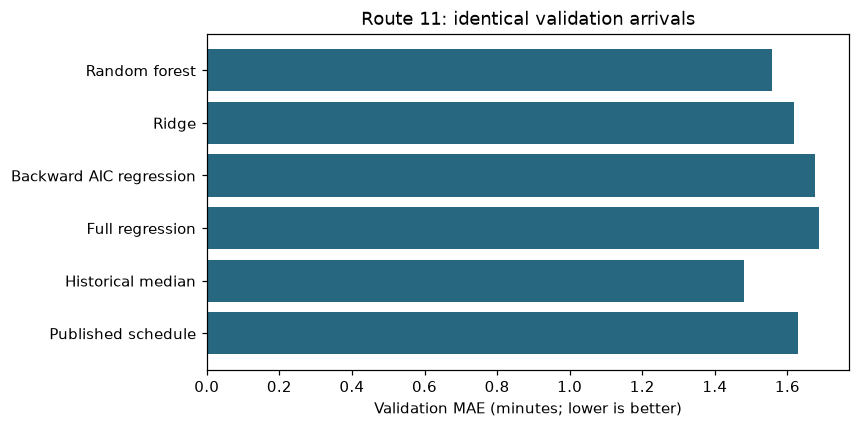

In [13]:
validation_predictions = validation[["source_row", "service_date", "bus_id", "stop_id", "direction_id", "scheduled_arrival", "actual_arrival", TARGET]].copy()
score_rows = []
for name in METHODS:
    pred, settings = predict_procedure(name, train, validation)
    validation_predictions[name] = pred
    score_rows.append({"method": name, "chosen_by_training_folds": name == chosen_method, "settings": settings, "MAE_minutes": mean_absolute_error(validation[TARGET], pred), "RMSE_minutes": np.sqrt(mean_squared_error(validation[TARGET], pred)), "validation_R2": r2_score(validation[TARGET], pred)})
validation_results = pd.DataFrame(score_rows)
display(validation_results.round(3))
validation_predictions["predicted_arrival"] = validation_predictions.scheduled_arrival + pd.to_timedelta(validation_predictions[chosen_method], unit="min")
validation_predictions["absolute_error_minutes"] = (validation_predictions[chosen_method] - validation[TARGET]).abs()
print("Chosen approach:", chosen_method)
display(validation_predictions[["source_row", "scheduled_arrival", "actual_arrival", "predicted_arrival", "absolute_error_minutes"]].head(8))
for group in ["service_date", "direction_id", "bus_id"]:
    print("Errors by", group)
    display(validation_predictions.groupby(group).absolute_error_minutes.agg(["size", "mean"]).rename(columns={"mean": "MAE_minutes"}))
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(validation_results.method, validation_results.MAE_minutes, color="#286780")
ax.set(xlabel="Validation MAE (minutes; lower is better)", title="Route 11: identical validation arrivals")
fig.tight_layout()
plt.show()

## Visual guide - demonstrate the results

The earlier bar chart compares **average** error across methods. The next figures show individual misses, stability across dates, and what the fitted model learns about hour.

These plots use the same training/validation split and chosen model. They do not tune it or access final-test outcomes.

### Graph 1. Actual versus predicted arrival delay

Each point is one validation arrival. A perfect prediction lies on the dashed diagonal. Compare using the schedule alone (zero predicted delay) with our training-fold-chosen method. Below the diagonal means we underestimated delay; above means we overestimated it. The axes show minutes relative to schedule, so a predicted delay of 3 minutes means adding 3 minutes to the published arrival time.

**Discuss:** which large delays remain difficult? Improving an average does not mean every arrival improves.

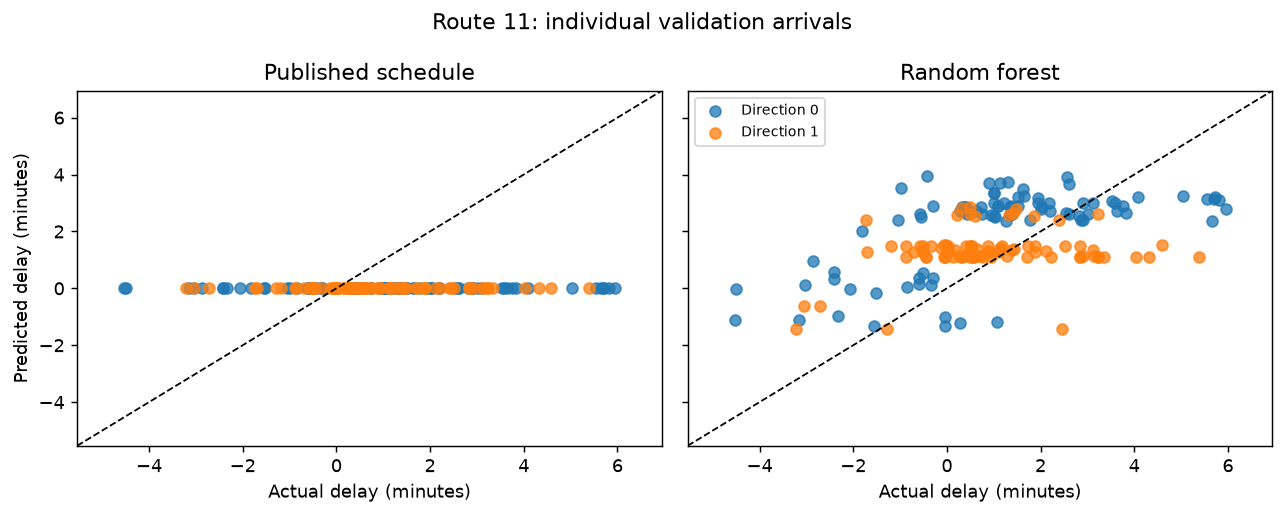

In [14]:
actual_delay = validation_predictions[TARGET].to_numpy()
model_delay = validation_predictions[chosen_method].to_numpy()
limits = [min(actual_delay.min(), model_delay.min(), 0) - 1,
          max(actual_delay.max(), model_delay.max(), 0) + 1]
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, name in zip(axes, ["Published schedule", chosen_method]):
    predicted = validation_predictions[name].to_numpy()
    for direction in sorted(validation_predictions.direction_id.unique()):
        mask = validation_predictions.direction_id.eq(direction)
        ax.scatter(actual_delay[mask], predicted[mask], alpha=0.75, label=f"Direction {direction}")
    ax.plot(limits, limits, "k--", linewidth=1)
    ax.set(xlim=limits, ylim=limits, xlabel="Actual delay (minutes)", title=name)
axes[0].set_ylabel("Predicted delay (minutes)")
axes[1].legend(fontsize=8)
fig.suptitle("Route 11: individual validation arrivals", fontsize=12)
fig.tight_layout()
plt.show()

### Graph 2. Error by validation date

Each group of bars describes one whole date. Lower bars mean better prediction. Counts above each group show how many arrivals contribute; some dates have fewer usable matches.

**Discuss:** does the model improve on the schedule every day, or is its overall improvement driven by one date? This is descriptive error analysis, not a reason to remove a difficult date.

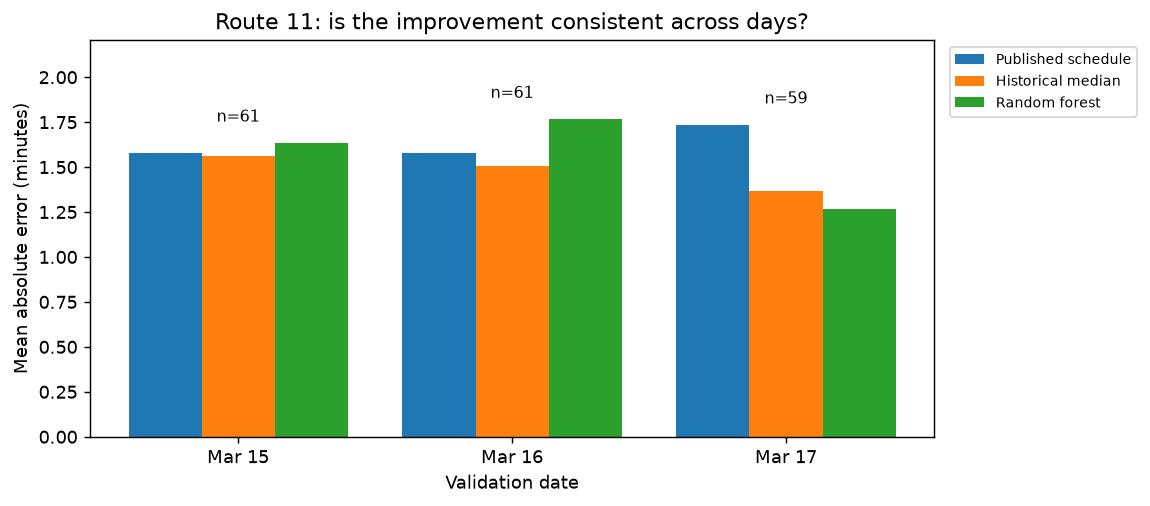

,arrivals,Published schedule,Historical median,Random forest
service_date,,,,
2023-03-15,61,1.577,1.564,1.633
2023-03-16,61,1.577,1.507,1.765
2023-03-17,59,1.734,1.368,1.267


In [15]:
comparison_methods = list(dict.fromkeys(["Published schedule", "Historical median", chosen_method]))
daily = validation_predictions.groupby("service_date").size().to_frame("arrivals")
for name in comparison_methods:
    errors = (validation_predictions[name] - validation_predictions[TARGET]).abs()
    daily[name] = errors.groupby(validation_predictions.service_date).mean()
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(daily))
width = 0.8 / len(comparison_methods)
for j, name in enumerate(comparison_methods):
    ax.bar(x + (j - (len(comparison_methods)-1)/2)*width, daily[name], width, label=name)
for j, (_, row) in enumerate(daily.iterrows()):
    ax.text(j, row[comparison_methods].max()+0.12, f"n={int(row.arrivals)}", ha="center", fontsize=9)
ax.set_xticks(x, daily.index.strftime("%b %d"))
ax.set(xlabel="Validation date", ylabel="Mean absolute error (minutes)", title="Route 11: is the improvement consistent across days?")
ax.set_ylim(0, daily[comparison_methods].to_numpy().max()*1.25)
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
plt.show()
display(daily.round(3))

### Graph 3. What happens to predictions across the day?

Hold stop ID and weekday fixed, then plot each direction's predictions across its **observed training hours for that stop and weekday**. Model fitting still uses all training dates; the plotted inputs vary hour while keeping weekday and direction fixed. We do not create combinations outside the observed support.

The dashed horizontal line is the historical median prediction. Both direction curves use the same fixed stop; no new stop/direction combinations are invented. This is a demonstration of the model's learned associations, **not evidence that changing the hour causes a delay**, and not an evaluation on unseen data. No recent actual arrival or passenger counts enter these inputs.

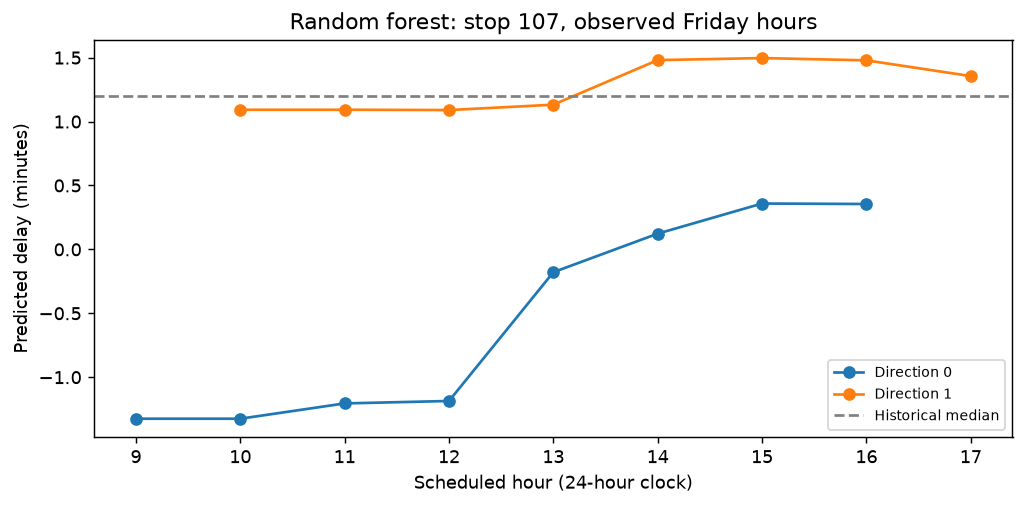

,direction_id,scheduled_hour,weekday,stop_id,predicted_delay_minutes
0,0,9,Friday,107,-1.325
1,0,10,Friday,107,-1.325
2,0,11,Friday,107,-1.205
3,0,12,Friday,107,-1.186
4,0,13,Friday,107,-0.179
5,0,14,Friday,107,0.123
6,0,15,Friday,107,0.359
7,0,16,Friday,107,0.355
8,1,10,Friday,107,1.092
9,1,11,Friday,107,1.092


In [16]:
shared_stops = train.groupby("stop_id").direction_id.nunique()
demo_stop = shared_stops.loc[shared_stops.eq(2)].index[0] if shared_stops.eq(2).any() else train.stop_id.mode().iloc[0]
stop_training = train.loc[train.stop_id.eq(demo_stop)]
demo_weekday = stop_training.weekday.mode().iloc[0]
demo_inputs = (stop_training.loc[stop_training.weekday.eq(demo_weekday), GROUPS]
               .drop_duplicates().sort_values(["direction_id", "scheduled_hour"]))
demo_prediction, demo_settings = predict_procedure(chosen_method, train, demo_inputs)
demo = demo_inputs.copy()
demo["predicted_delay_minutes"] = demo_prediction
fig, ax = plt.subplots(figsize=(8, 4))
for direction, part in demo.groupby("direction_id"):
    ax.plot(part.scheduled_hour, part.predicted_delay_minutes, marker="o", label=f"Direction {direction}")
ax.axhline(train[TARGET].median(), color="gray", linestyle="--", label="Historical median")
ax.set(xlabel="Scheduled hour (24-hour clock)", ylabel="Predicted delay (minutes)",
       title=f"{chosen_method}: stop {demo_stop}, observed {demo_weekday} hours")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
display(demo.reset_index(drop=True).round(3))

### How to present these figures

1. Begin with the average-error bar chart: which approach has the smallest average miss?
2. Show the scatter plots: averages hide large individual misses.
3. Show the date bars: ask whether the benefit is stable across days.
4. Show the hour curves: explain what the model predicts when known schedule inputs change.

Always mention that matches are provisional and only the retained intermediate timepoints are represented. The optional PNG files in the download package can be used in slides.

## 8. Results explained

### How much data did we model?
The original workbook has **23,365 stop visits**, **17 observed dates**, and **3 buses**. We retain **781 intermediate development arrivals**: **600 training** and **181 validation** observations. These cover the retained published intermediate timepoints listed above, not every Route 11 stop. **1177 other timepoint records** remain held for review; untimed stops are outside this target population.

### Are the targets verified?
No. Matches have consistent patterns and other-timepoint support, but remain inferred assignments rather than independently confirmed GTFS trip IDs. A 20-minute target matching window restricts inclusion and may omit severe delays or ambiguous visits. Our scores describe retained timepoints, not route-wide performance or a deployable live system.

### What did the regression tell us?
The full regression has training R² **0.212**, adjusted R² **0.201**, classical F-statistic **19.85**, ordinary F-test p-value **1.23e-26**, AIC **2684.70**, and BIC **2724.27**. These describe training association under assumptions; repeated observations and only ten days limit significance claims. Read the clustered uncertainty table too.

Backward AIC retains **direction_id, weekday, stop_id**. Its AIC is **2684.04**, BIC **2719.22**. Route 11 is allowed to choose differently from Route 7.

### Which procedure won?
Training-date folds select **Random forest**, with MAE **1.806 minutes**. On the later validation dates its MAE is **1.559 minutes**. The lowest validation MAE belongs to **Historical median** at **1.481 minutes**. Report any disagreement; do not silently reselect on validation or claim a universal winner from three dates.

### Are predictions better than the timetable?
The published timetable's validation MAE is **1.628 minutes**. The median scores **1.481 minutes**, a **9.0% reduction** (a negative reduction means worse). The training-fold-chosen method scores **1.559 minutes**, a **4.3% reduction**. These percentages are reductions in average absolute error, not classification accuracy. We compare with published times, not Navigator's live estimate.

### Did selection, regularization, or a forest help?
Validation MAEs are full regression **1.686**, backward selection **1.677**, ridge **1.618**, and forest **1.559 minutes**. Compare these with the median **1.481** as well as the schedule **1.628**. Better training AIC does not guarantee lower future-date MAE.

### Can we compare Route 11 and Route 7 directly?
The development calendar boundaries match, but modeled stops, sample counts, and selection patterns differ. Report each route's error and improvement over its own baseline. A smaller raw MAE is not proof that a route is inherently easier or a model transfers universally.

### Practical synthesis

- **The median is best by validation MAE:** about **1 minute 29 seconds** of average absolute error, versus **1 minute 38 seconds** for the published timetable. That is roughly **9 seconds less error**, or **9%**, on this retained sample. The gain is modest.
- **The forest is the training-fold-selected procedure:** it scores about **1 minute 34 seconds** validation MAE. It beats the schedule overall, but not the median on MAE. Its RMSE (1.864 minutes) is lower than the median's (1.946 minutes), so the answer also depends on how strongly we penalize large errors. Our selection criterion remains MAE; we do not change it after seeing this table.
- **Benefits vary across dates:** the forest is worse than the schedule on March 15 and 16 but better on March 17. Its overall improvement is not consistent day by day. The daily graph makes this visible.
- **Backward selection removed hour:** the full model estimates only about +0.031 minutes of delay per hour later, with an ordinary interval spanning zero. Direction, weekday, and stop ID remain. AIC improves only about 0.66, and validation MAE improves by only about **0.6 seconds** compared with full regression. This is simplification, not a substantial predictive breakthrough.
- **Stop ID matters to the design:** unlike Route 3, Health Department occurs in both directions, so stop identity and direction are separate inputs. Do not extrapolate to stop/direction combinations absent from training.
- **Keep the claim scoped:** these are 181 retained validation arrivals at three published intermediate stops, not all 23,365 raw visits. Ambiguous, flagged, terminal, and unsupported records remain outside this model. Labels are provisional and final-test dates remain unscored.


### Coefficients in plain language

- Per hour later in the schedule, estimated delay changes by **+0.031 minutes**, holding other inputs fixed (ordinary 95% interval -0.022 to +0.085).
- For `direction_id_1` versus its reference category, estimated delay changes by **+1.741 minutes**, holding other inputs fixed (ordinary 95% interval +1.039 to +2.444).
- For `weekday_Monday` versus its reference category, estimated delay changes by **-0.453 minutes**, holding other inputs fixed (ordinary 95% interval -1.020 to +0.114).
- For `weekday_Thursday` versus its reference category, estimated delay changes by **+0.963 minutes**, holding other inputs fixed (ordinary 95% interval +0.390 to +1.537).
- For `weekday_Tuesday` versus its reference category, estimated delay changes by **-0.142 minutes**, holding other inputs fixed (ordinary 95% interval -0.710 to +0.426).
- For `weekday_Wednesday` versus its reference category, estimated delay changes by **+0.626 minutes**, holding other inputs fixed (ordinary 95% interval +0.059 to +1.193).
- For `stop_id_1234` versus its reference category, estimated delay changes by **+3.028 minutes**, holding other inputs fixed (ordinary 95% interval +2.449 to +3.607).
- For `stop_id_1235` versus its reference category, estimated delay changes by **-0.459 minutes**, holding other inputs fixed (ordinary 95% interval -1.038 to +0.121).

Reference direction is 0; reference weekday is the alphabetically first observed training weekday. Stop is included separately from direction. Direction/stop effects are estimated only for observed combinations, so do not extrapolate to unobserved combinations. Effects are associations, not causal. The hour-zero intercept is outside observed service hours.

## 9. Research questions - with answers

**Why are most raw records not training rows?**  
They may be untimed stops, reserved dates, terminal visits, or records needing linkage review. An absent schedule-delay label does not mean a raw row is invalid.

**Why pool buses?**  
Samples per bus are small and bus identity is entangled with operating dates. Pool observations, split whole dates, and inspect errors by bus/date afterward.

**Why keep unusually large delays?**  
An extreme value can be genuine. Training-only IQR flags identify review candidates; no rows are deleted just to improve prediction scores.

**Why include stop ID as well as direction?**  
Health Department appears in both directions while the two Walmart locations are directional. Unlike the Route 3 sample, stop and direction do not encode the same split; both can carry information. Inspect design rank before interpreting coefficients.

**How is ridge tuning protected against look-ahead?**  
Only inner chronological folds within an outer training portion select alpha. The outer dates evaluate the full tuning procedure. Final validation dates do not choose alpha.

**What else could leak future information?**  
Target-stop passenger counts, later observations used as predictors, fitting encoders/selection on evaluation rows, and choosing rules using final-test outcomes. Retrospective journey evidence supports provisional labels only; it is never a predictor.

**Do p-values decide the best predictor set?**  
No. Consider effect size, dependence, redundancy, prediction-time availability, complexity, and later-date error. Selection also makes naive post-selection significance claims unreliable.

**What transfers to Route 711?**  
The procedure and reporting format, not fitted coefficients or hard-coded timed-stop IDs. Check each route's patterns, calendar, terminal semantics, samples, and splits before fitting.

**Can we generalize to all RTS service now?**  
No. This adds one route's retained timepoints. Separate-versus-pooled and leave-one-route-out experiments can follow after route-level audits, with chronology preserved. Route 711's weekend-heavy sample needs special care.

**What remains before a final claim?**  
Resolve linkage concerns, freeze the complete preparation/feature/selection rules, refit on approved development data, and score reserved final dates once.

**Where did the inputs come from?**  
Richard Borzi / University of Florida, data supplied by Gainesville RTS, CC BY 4.0: [Route 11 record](https://zenodo.org/records/10034723). Historical [Spring 2023 GTFS](https://www.ftis.org/PostFileDownload.aspx?id=602A0). Keep source attribution when sharing derived work.

## Optional - save outputs for later comparisons

Uncomment if needed. These are new outputs, not required inputs. Retain split and linkage status in research records but never use them as predictors.

In [17]:
# cleaned.to_csv("Route11_Development.csv", index=False)
# held.to_csv("Route11_Held_For_Review.csv", index=False)
# validation_results.to_csv("Route11_Validation_Results.csv", index=False)
# fold_results.to_csv("Route11_Training_Date_Folds.csv", index=False)